# Comparación de modelos de clasificación · Churn E-commerce (Equipo 5, TI3008C)

**Objetivo:** reproducir en Python los modelos que entrenamos en SAS Viya Model Studio, compararlos con las
mismas métricas, dibujar sus curvas ROC y dejar listo el modelo campeón (**Gradient Boosting**) para predecir
la probabilidad de abandono de un cliente nuevo.

**Variables:** las 11 que quedaron en el modelo final de SAS (sección 4).

**Modelos (todos de clasificación, objetivo `Churned` 0/1):**
1. Árbol de decisión
2. Bosque aleatorio (random forest)
3. Red neuronal (perceptrón multicapa)
4. Regresión logística
5. Gradient Boosting (campeón en SAS)

**Reglas que seguimos (las mismas de la limpieza acordada y del profesor):**
- El dataset original ya se dividió **80/20 antes de limpiar** (40,000 / 10,000, estratificado, 28.9% de churn en ambos). **No se vuelve a dividir.**
- **Train (80%)**: el que limpiamos (versión A v2) y con **log(x+1)** en 8 variables.
- **Test (20%)**: **no se imputa**; solo tiene las mismas transformaciones (logaritmos y las correcciones fijas de escala ×1.3 / ×1.2 aprendidas en train). Sus vacíos se quedan vacíos.
- Dentro del 80%, los modelos se entrenan con **70% entrenamiento / 30% validación / 0% testeo**, igual que en Model Studio.
- El campeón se elige con **validación**; el **test** solo se usa al final para el score, como en SAS.
- Todo valor que use un modelo (por ejemplo la mediana para rellenar un vacío dentro de la red neuronal) se calcula **solo con la parte de entrenamiento**.

## 1. Librerías
Solo usamos `pandas`, `numpy`, `scikit-learn` y `matplotlib`, que vienen instaladas en Colab.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
SEMILLA = 0          # misma semilla en todo el notebook para que los resultados se repitan
pd.set_option("display.width", 200)
print("Listo")

Listo


## 2. Cargar train y test
Los archivos están en la carpeta `Pruebas_modelos_churn/Transformados/`. Usan **coma como separador y coma decimal**
(por ejemplo `"41,0"`), por eso se leen con `decimal=","`.

En Colab, la celda pide subir los dos archivos. En la computadora los lee directo de la carpeta.

In [2]:
from pathlib import Path

ARCHIVO_TRAIN, ARCHIVO_TEST = "train_log.csv", "test_log.csv"
if not (Path(ARCHIVO_TRAIN).exists() and Path(ARCHIVO_TEST).exists()):
    try:
        from google.colab import files  # solo existe en Colab
        print("Sube train_log.csv y test_log.csv")
        files.upload()
    except ImportError:
        pass

train = pd.read_csv(ARCHIVO_TRAIN, decimal=",")
test = pd.read_csv(ARCHIVO_TEST, decimal=",")
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (40000, 25) | Test: (10000, 25)


,Age,Gender,Country,City,log_Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,log_Wishlist_Items,log_Total_Purchases,log_Average_Order_Value,log_Days_Since_Last_Purchase,Discount_Usage_Rate,log_Returns_Rate,Email_Open_Rate,Customer_Service_Calls,log_Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,log_Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,24.0,Male,USA,Houston,0.788457,9.0,38.9,7.5,53.9,2.302585,2.484907,4.223910,2.890372,45.9,1.335001,46.1,9.0,1.098612,22.2,25.5,2.0,6.427087,2187.0,0,Q2
1,49.0,Male,USA,New York,1.458615,28.0,58.4,21.3,12.2,2.639057,3.465736,4.770430,3.465736,59.3,1.481605,42.4,3.0,1.945910,72.6,48.2,1.0,8.161030,3173.0,0,Q2
2,56.0,Female,Germany,Hamburg,0.993252,9.0,26.8,11.5,67.6,1.386294,2.639057,5.158365,1.791759,28.9,1.791759,12.4,7.0,1.609438,26.2,19.2,2.0,7.794419,2582.0,1,Q3
3,69.0,Male,USA,Los Angeles,1.029619,11.0,44.2,13.4,36.0,1.609438,2.995732,4.548176,0.693147,59.2,2.261763,16.2,8.0,2.197225,13.7,26.9,4.0,7.268746,3789.0,0,Q4
4,47.0,Female,India,Hyderabad,1.774952,12.0,33.4,12.5,60.6,2.302585,2.772589,4.898586,3.091042,49.3,1.252763,39.1,2.0,1.609438,42.3,21.2,2.0,7.749193,1540.0,0,Q3


## 3. Verificar que los datos cumplen las reglas acordadas
Antes de entrenar revisamos que no se haya colado ningún error:
- mismas columnas y en el mismo orden en train y test;
- train sin vacíos (ya se limpió) y test con sus vacíos originales (no se imputó);
- misma tasa de churn (split estratificado);
- las 8 variables en logaritmo existen en los dos y no tienen negativos ni infinitos (log(x+1) de algo ≥ 0 siempre es ≥ 0).

In [3]:
VARIABLES_LOG = ["log_Membership_Years", "log_Wishlist_Items", "log_Total_Purchases",
                 "log_Average_Order_Value", "log_Days_Since_Last_Purchase", "log_Returns_Rate",
                 "log_Product_Reviews_Written", "log_Lifetime_Value"]

revision = {
    "Mismas columnas y orden": list(train.columns) == list(test.columns),
    "Train sin vacíos": int(train.isna().sum().sum()) == 0,
    "Test conserva sus vacíos (no imputado)": int(test.isna().sum().sum()) > 0,
    "Churn train = churn test": round(train["Churned"].mean(), 3) == round(test["Churned"].mean(), 3),
    "8 variables log en los dos": all(c in train and c in test for c in VARIABLES_LOG),
    "Logs sin negativos ni infinitos": bool(np.isfinite(train[VARIABLES_LOG]).all().all()
                                             and (train[VARIABLES_LOG] >= 0).all().all()
                                             and (test[VARIABLES_LOG].dropna() >= 0).all().all()),
    "Edad de train en rango 18–80": bool(train["Age"].between(18, 80).all()),
}
for regla, ok in revision.items():
    print(("✅" if ok else "❌"), regla)
print(f"\nChurn train: {train['Churned'].mean():.1%} | Churn test: {test['Churned'].mean():.1%}")
print("\nVacíos en test (se quedan así; los modelos los manejan sin rellenar el archivo):")
print(test.isna().sum()[test.isna().sum() > 0].to_string())

✅ Mismas columnas y orden
✅ Train sin vacíos
✅ Test conserva sus vacíos (no imputado)
✅ Churn train = churn test
✅ 8 variables log en los dos
✅ Logs sin negativos ni infinitos
✅ Edad de train en rango 18–80

Churn train: 28.9% | Churn test: 28.9%

Vacíos en test (se quedan así; los modelos los manejan sin rellenar el archivo):
Age                               525
log_Membership_Years               15
Session_Duration_Avg              710
Pages_Per_Session                 641
Cart_Abandonment_Rate               8
log_Wishlist_Items                790
log_Total_Purchases                 8
log_Days_Since_Last_Purchase      588
Discount_Usage_Rate               672
log_Returns_Rate                  896
Email_Open_Rate                   510
Customer_Service_Calls             28
log_Product_Reviews_Written       728
Social_Media_Engagement_Score    1235
Mobile_App_Usage                  987
Payment_Method_Diversity          491
Credit_Balance                   1147


## 4. Variables de entrada: las 11 del modelo final de SAS
En Model Studio quitamos variables en dos rondas, según su importancia en el gradient boosting:
- **Primera ronda (8):** Country, log_Average_Order_Value, Social_Media_Engagement_Score, Credit_Balance,
  log_Membership_Years, Payment_Method_Diversity, Signup_Quarter y Gender.
- **Segunda ronda (5):** Mobile_App_Usage, Login_Frequency, log_Product_Reviews_Written, log_Wishlist_Items y Session_Duration_Avg.

Quedan **11 variables de entrada** (10 numéricas y 1 categórica). Se usan las mismas en los cinco modelos, porque en SAS el rol
*Rechazada* se pone en los datos del proyecto y aplica a todos los pipelines. Siguiendo la regla del profe, las que no se usan en train
tampoco se usan en test.
- **Objetivo:** `Churned`.
- Las variables con logaritmo se usan **solo en su versión log(x+1)**.
- `City` (40 ciudades) se convierte en columnas 0/1 (*one-hot*).

In [4]:
OBJETIVO = "Churned"
NUMERICAS = ["log_Lifetime_Value", "Cart_Abandonment_Rate", "Customer_Service_Calls", "Discount_Usage_Rate",
             "log_Days_Since_Last_Purchase", "Age", "Email_Open_Rate", "log_Total_Purchases", "log_Returns_Rate",
             "Pages_Per_Session"]
CATEGORICAS = ["City"]
RECHAZADAS = [c for c in train.columns if c not in NUMERICAS + CATEGORICAS + [OBJETIVO]]
print(len(NUMERICAS) + len(CATEGORICAS), "variables de entrada")
print(len(NUMERICAS), "numéricas:", NUMERICAS)
print(len(CATEGORICAS), "categórica:", CATEGORICAS)
print(len(RECHAZADAS), "rechazadas:", RECHAZADAS)

11 variables de entrada
10 numéricas: ['log_Lifetime_Value', 'Cart_Abandonment_Rate', 'Customer_Service_Calls', 'Discount_Usage_Rate', 'log_Days_Since_Last_Purchase', 'Age', 'Email_Open_Rate', 'log_Total_Purchases', 'log_Returns_Rate', 'Pages_Per_Session']
1 categórica: ['City']
13 rechazadas: ['Gender', 'Country', 'log_Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'log_Wishlist_Items', 'log_Average_Order_Value', 'log_Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Credit_Balance', 'Signup_Quarter']


## 5. Partición 70/30 dentro del 80% (igual que Model Studio)
El 80% se divide en **70% entrenamiento** y **30% validación**, estratificado por `Churned`.
El test (20%) no se toca hasta el final.

In [5]:
X = train[NUMERICAS + CATEGORICAS]
y = train[OBJETIVO]
X_ent, X_val, y_ent, y_val = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_test, y_test = test[NUMERICAS + CATEGORICAS], test[OBJETIVO]

print(f"Entrenamiento: {len(X_ent):,} ({y_ent.mean():.1%} churn)")
print(f"Validación:    {len(X_val):,} ({y_val.mean():.1%} churn)")
print(f"Test:          {len(X_test):,} ({y_test.mean():.1%} churn)")

Entrenamiento: 28,000 (28.9% churn)
Validación:    12,000 (28.9% churn)
Test:          10,000 (28.9% churn)


## 6. Cómo trata cada modelo los vacíos del test
El test **no se imputa** (regla del profesor), pero tiene vacíos. Igual que en SAS:
- **Árbol, bosque y gradient boosting** aceptan vacíos directamente: en cada división aprenden hacia qué rama mandar a los clientes sin dato.
- **Red neuronal y regresión logística** no pueden operar con vacíos. Por eso, *dentro del modelo*, el vacío se reemplaza por la **mediana calculada con la parte de entrenamiento** (70%) y se estandarizan las variables. Esto es parte del modelo (como el nodo de imputación del pipeline en SAS): el archivo de test no se modifica y no se usa ningún valor calculado con él.

In [6]:
def categoricas():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Para árboles: números tal cual (con sus vacíos) + categóricas en 0/1
prep_arboles = ColumnTransformer([("num", "passthrough", NUMERICAS),
                                  ("cat", categoricas(), CATEGORICAS)])

# Para red neuronal y logística: mediana de entrenamiento + estandarizar
prep_escalado = ColumnTransformer([
    ("num", Pipeline([("mediana", SimpleImputer(strategy="median")), ("escala", StandardScaler())]), NUMERICAS),
    ("cat", categoricas(), CATEGORICAS)])
print("Preprocesamiento definido")

Preprocesamiento definido


## 7. Definir los cinco modelos
Usamos parámetros sencillos y razonables (parecidos a los que trae SAS por defecto) para que la comparación sea justa:

| Modelo | Parámetros principales | Por qué |
|---|---|---|
| Árbol de decisión | profundidad máx. 6, mínimo 50 clientes por hoja | Un árbol muy profundo memoriza el entrenamiento |
| Bosque aleatorio | 300 árboles, mínimo 5 clientes por hoja | Promediar muchos árboles reduce el error |
| Red neuronal | 1 capa oculta de 32 neuronas, paro temprano | Paro temprano evita sobreajuste |
| Regresión logística | sin balancear | Modelo lineal de referencia |
| Gradient Boosting | 300 iteraciones, tasa 0.05, hojas de 31, paro temprano | Cada árbol corrige los errores del anterior |

In [7]:
modelos = {
    "Árbol de decisión": Pipeline([("prep", prep_arboles), ("modelo",
        DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEMILLA))]),
    "Bosque aleatorio": Pipeline([("prep", prep_arboles), ("modelo",
        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEMILLA))]),
    "Red neuronal": Pipeline([("prep", prep_escalado), ("modelo",
        MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-3, max_iter=300, early_stopping=True,
                      random_state=SEMILLA))]),
    "Regresión logística": Pipeline([("prep", prep_escalado), ("modelo",
        LogisticRegression(max_iter=2000))]),
    "Gradient Boosting": Pipeline([("prep", prep_arboles), ("modelo",
        HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                       early_stopping=True, random_state=SEMILLA))]),
}
print(list(modelos))

['Árbol de decisión', 'Bosque aleatorio', 'Red neuronal', 'Regresión logística', 'Gradient Boosting']


## 8. Entrenar los cinco modelos (solo con el 70%)

In [8]:
import time

for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_ent, y_ent)
    print(f"{nombre:<22} entrenado en {time.time() - inicio:5.1f} s")

Árbol de decisión      entrenado en   0.2 s
Bosque aleatorio       entrenado en   6.0 s
Red neuronal           entrenado en   2.0 s
Regresión logística    entrenado en   0.1 s
Gradient Boosting      entrenado en   1.5 s


## 9. Métricas de comparación
Con un corte de **0.5** (la misma regla de decisión que en Intelligent Decisioning: si la probabilidad de churn > 0.5 → campaña "No te vayas"):

| Métrica | Qué mide |
|---|---|
| **Accuracy** | % de clientes bien clasificados (la línea base, decir siempre "no se va", es 71.1%) |
| **Precisión** | De los que el modelo marca como "se va", cuántos sí se fueron |
| **Recall (sensibilidad)** | De los que sí se fueron, cuántos detectó el modelo |
| **F1** | Balance entre precisión y recall |
| **AUC** | Área bajo la curva ROC: qué tan bien ordena a los clientes por riesgo (0.5 = al azar, 1 = perfecto) |
| **KS** | Máxima separación entre la curva de los que se van y los que se quedan (SAS la usa para elegir campeón) |

Calculamos todo en **validación** (para elegir) y en **test** (score final).

In [9]:
CORTE = 0.5

def metricas(y_real, prob, corte=CORTE):
    pred = (prob > corte).astype(int)
    fpr, tpr, _ = roc_curve(y_real, prob)
    return {"Accuracy": accuracy_score(y_real, pred), "Precisión": precision_score(y_real, pred),
            "Recall": recall_score(y_real, pred), "F1": f1_score(y_real, pred),
            "AUC": roc_auc_score(y_real, prob), "KS": float(np.max(tpr - fpr)),
            "Error de clasificación": 1 - accuracy_score(y_real, pred)}

probabilidades = {"Validación": {}, "Test": {}}
filas = []
for nombre, modelo in modelos.items():
    for particion, (Xp, yp) in {"Validación": (X_val, y_val), "Test": (X_test, y_test)}.items():
        prob = modelo.predict_proba(Xp)[:, 1]
        probabilidades[particion][nombre] = prob
        filas.append({"Modelo": nombre, "Partición": particion, **metricas(yp, prob)})

resultados = pd.DataFrame(filas)
tabla_val = resultados[resultados["Partición"] == "Validación"].set_index("Modelo").drop(columns="Partición")
tabla_test = resultados[resultados["Partición"] == "Test"].set_index("Modelo").drop(columns="Partición")
print("VALIDACIÓN (30% del train) — ordenado por AUC")
print(tabla_val.sort_values("AUC", ascending=False).round(3).to_string())
print("\nTEST (20%, score final)")
print(tabla_test.sort_values("AUC", ascending=False).round(3).to_string())

VALIDACIÓN (30% del train) — ordenado por AUC
                     Accuracy  Precisión  Recall     F1    AUC     KS  Error de clasificación
Modelo                                                                                       
Gradient Boosting       0.909      0.893   0.780  0.833  0.920  0.763                   0.091
Bosque aleatorio        0.907      0.905   0.757  0.824  0.918  0.762                   0.093
Red neuronal            0.875      0.830   0.714  0.767  0.899  0.696                   0.125
Árbol de decisión       0.880      0.865   0.693  0.769  0.895  0.684                   0.120
Regresión logística     0.761      0.651   0.372  0.473  0.759  0.391                   0.239

TEST (20%, score final)
                     Accuracy  Precisión  Recall     F1    AUC     KS  Error de clasificación
Modelo                                                                                       
Gradient Boosting       0.911      0.898   0.781  0.836  0.925  0.774              

## 10. Elegir el modelo campeón
El campeón se elige con **validación** (no con test, para no hacer trampa). Usamos el **AUC** y revisamos que el KS y el error de clasificación digan lo mismo.

In [10]:
campeon = tabla_val["AUC"].idxmax()
print("Campeón por AUC en validación:", campeon)
print("Campeón por KS en validación:  ", tabla_val["KS"].idxmax())
print("Campeón por menor error:       ", tabla_val["Error de clasificación"].idxmin())

comparacion = tabla_val[["Accuracy", "Recall", "AUC"]].join(
    tabla_test[["Accuracy", "Recall", "AUC"]], lsuffix=" val", rsuffix=" test")
comparacion["Diferencia AUC (val − test)"] = comparacion["AUC val"] - comparacion["AUC test"]
print("\n¿Se sostiene en test? (si la diferencia es pequeña, el modelo no está sobreajustado)")
print(comparacion.sort_values("AUC test", ascending=False).round(3).to_string())

Campeón por AUC en validación: Gradient Boosting
Campeón por KS en validación:   Gradient Boosting
Campeón por menor error:        Gradient Boosting

¿Se sostiene en test? (si la diferencia es pequeña, el modelo no está sobreajustado)
                     Accuracy val  Recall val  AUC val  Accuracy test  Recall test  AUC test  Diferencia AUC (val − test)
Modelo                                                                                                                   
Gradient Boosting           0.909       0.780    0.920          0.911        0.781     0.925                       -0.005
Bosque aleatorio            0.907       0.757    0.918          0.907        0.761     0.925                       -0.007
Red neuronal                0.875       0.714    0.899          0.875        0.719     0.904                       -0.005
Árbol de decisión           0.880       0.693    0.895          0.876        0.694     0.897                       -0.002
Regresión logística         0.761

## 11. Gráfica de barras: comparación de métricas en test

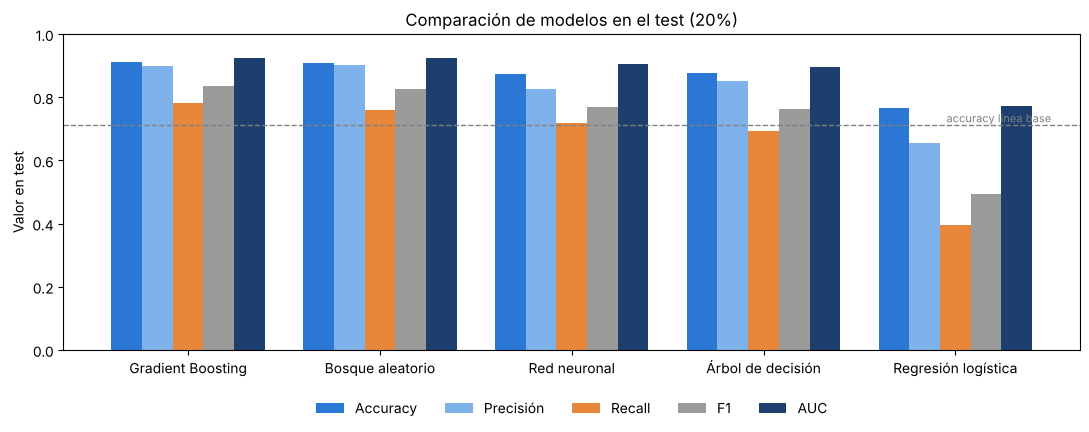

In [11]:
orden = tabla_test.sort_values("AUC", ascending=False).index
grafica = tabla_test.loc[orden, ["Accuracy", "Precisión", "Recall", "F1", "AUC"]]
ax = grafica.plot(kind="bar", figsize=(11, 4.5), width=0.8,
                  color=["#2a78d4", "#7fb2ea", "#e8873a", "#9b9b9b", "#1d3f6e"])
ax.set_ylim(0, 1)
ax.set_ylabel("Valor en test")
ax.set_xlabel("")
ax.set_title("Comparación de modelos en el test (20%)")
ax.axhline(1 - y_test.mean(), ls="--", color="gray", lw=1)
ax.text(len(orden) - 0.5, 1 - y_test.mean() + 0.01, "accuracy línea base", ha="right", color="gray", fontsize=8)
plt.xticks(rotation=0)
plt.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.tight_layout()
plt.show()

## 12. Curva ROC de todos los modelos (test)
Cada curva muestra, para todos los cortes posibles, cuántos de los que se van detecta el modelo (**TPR**, eje y)
contra cuántos de los que se quedan marca por error (**FPR**, eje x). Mientras más se pegue a la esquina superior izquierda, mejor.
La diagonal punteada es un modelo al azar (AUC = 0.5).

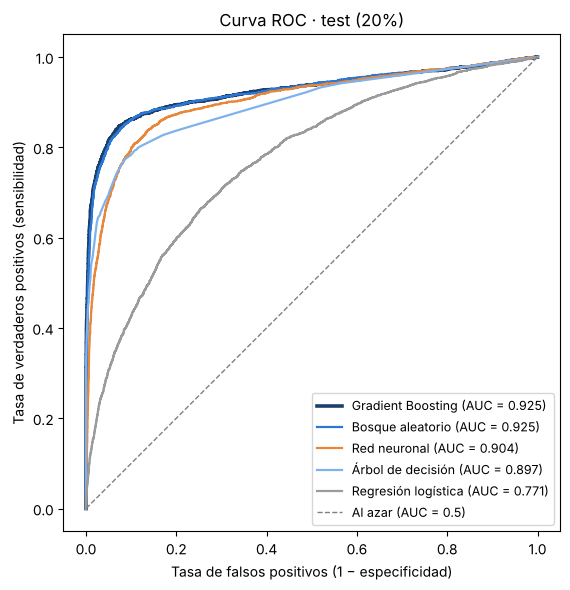

In [12]:
colores = {"Gradient Boosting": "#1d3f6e", "Bosque aleatorio": "#2a78d4", "Red neuronal": "#e8873a",
           "Regresión logística": "#9b9b9b", "Árbol de decisión": "#7fb2ea"}
fig, ax = plt.subplots(figsize=(6.5, 6))
puntos_roc = []
for nombre in orden:
    fpr, tpr, cortes = roc_curve(y_test, probabilidades["Test"][nombre])
    ax.plot(fpr, tpr, lw=2.6 if nombre == campeon else 1.6, color=colores[nombre],
            label=f"{nombre} (AUC = {tabla_test.loc[nombre, 'AUC']:.3f})")
    puntos_roc.append(pd.DataFrame({"Modelo": nombre, "FPR": fpr, "TPR": tpr, "Corte": cortes}))
ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Al azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.set_title("Curva ROC · test (20%)")
ax.legend(loc="lower right", fontsize=9)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 13. Modelo final: Gradient Boosting
### 13.1 Matriz de confusión en test (corte 0.5)

In [13]:
final = modelos["Gradient Boosting"]
prob_test = probabilidades["Test"]["Gradient Boosting"]
pred_test = (prob_test > CORTE).astype(int)
vn, fp, fn, vp = confusion_matrix(y_test, pred_test).ravel()
matriz = pd.DataFrame([[vn, fp], [fn, vp]], index=["Real: se queda (0)", "Real: se va (1)"],
                      columns=["Predicho: se queda (0)", "Predicho: se va (1)"])
print(matriz.to_string())
print(f"\nDe {vp + fn:,} clientes que sí se fueron, el modelo detectó {vp:,} ({vp / (vp + fn):.1%}).")
print(f"De {vp + fp:,} clientes a los que se les mandaría la campaña, {vp:,} sí se iban a ir ({vp / (vp + fp):.1%}).")

                    Predicho: se queda (0)  Predicho: se va (1)
Real: se queda (0)                    6853                  257
Real: se va (1)                        632                 2258

De 2,890 clientes que sí se fueron, el modelo detectó 2,258 (78.1%).
De 2,515 clientes a los que se les mandaría la campaña, 2,258 sí se iban a ir (89.8%).


### 13.2 ¿Qué variables usa más el Gradient Boosting?
Usamos **importancia por permutación** en validación: se revuelve una variable a la vez y se mide cuánto baja el AUC.
Si baja mucho, el modelo depende de esa variable.

                        Variable  Baja del AUC
0             log_Lifetime_Value        0.1745
1         Customer_Service_Calls        0.1330
2                            Age        0.0656
3          Cart_Abandonment_Rate        0.0540
4            Discount_Usage_Rate        0.0506
5   log_Days_Since_Last_Purchase        0.0259
6                Email_Open_Rate        0.0143
7            log_Total_Purchases        0.0103
8               log_Returns_Rate        0.0051
9              Pages_Per_Session        0.0030
10                          City       -0.0002


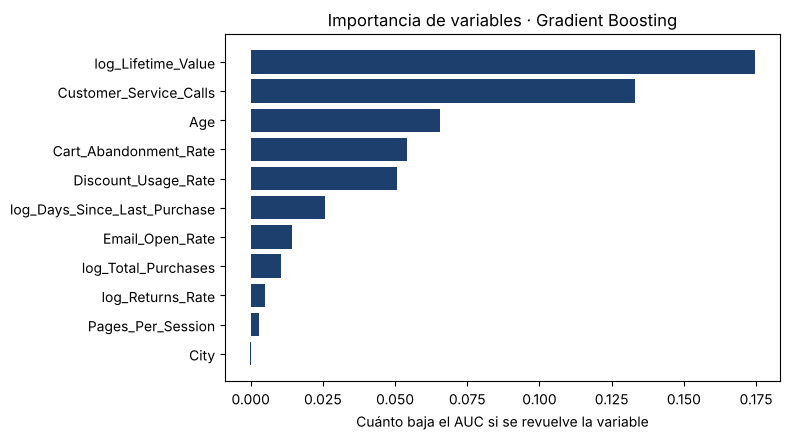

In [14]:
imp = permutation_importance(final, X_val, y_val, scoring="roc_auc", n_repeats=5,
                             random_state=SEMILLA, n_jobs=-1)
importancia = (pd.DataFrame({"Variable": X_val.columns, "Baja del AUC": imp.importances_mean})
               .sort_values("Baja del AUC", ascending=False).reset_index(drop=True))
print(importancia.head(12).round(4).to_string())
top = importancia.head(12).iloc[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top["Variable"], top["Baja del AUC"], color="#1d3f6e")
plt.xlabel("Cuánto baja el AUC si se revuelve la variable")
plt.title("Importancia de variables · Gradient Boosting")
plt.tight_layout()
plt.show()

## 14. Predecir con el Gradient Boosting metiéndole datos de un cliente
El usuario escribe los datos **en su escala normal** (años, compras, días…). La función saca **log(x+1)**
de las 8 variables, exactamente igual que en train y test, y le pide la probabilidad al modelo.
Después aplica la regla de decisión: **si la probabilidad de churn > 0.5 → campaña "No te vayas"**.

Si no se conoce un dato se puede dejar en `None`: el Gradient Boosting sabe qué hacer con un vacío (no lo rellenamos).

In [15]:
ORIGINALES_LOG = {c.replace("log_", ""): c for c in VARIABLES_LOG}  # "Total_Purchases" -> "log_Total_Purchases"

def preparar_cliente(datos):
    """Convierte un diccionario en escala original a las columnas que espera el modelo (con log(x+1))."""
    fila = {}
    for col in NUMERICAS + CATEGORICAS:
        original = col.replace("log_", "")
        valor = datos.get(original)
        if col in VARIABLES_LOG and valor is not None:
            valor = np.log1p(valor)          # log(x+1), igual que en train y test
        fila[col] = np.nan if valor is None else valor
    return pd.DataFrame([fila])

def predecir(datos, modelo=final, corte=CORTE):
    prob = float(modelo.predict_proba(preparar_cliente(datos))[:, 1][0])
    decision = "Enviar campaña \"No te vayas\"" if prob > corte else "No hacer nada"
    return prob, decision

cliente_ejemplo = {   # solo las 11 variables del modelo, en escala normal
    "Lifetime_Value": 250.0, "Cart_Abandonment_Rate": 85.0, "Customer_Service_Calls": 9,
    "Discount_Usage_Rate": 20.0, "Days_Since_Last_Purchase": 120, "Age": 34, "Email_Open_Rate": 10.0,
    "Total_Purchases": 4, "Returns_Rate": 8.0, "Pages_Per_Session": 4.0, "City": "Houston",
}
prob, decision = predecir(cliente_ejemplo)
print(f"Cliente en riesgo  → probabilidad de churn: {prob:.1%} → {decision}")

# Un cliente "típico": la mediana de train en escala original
tipico = {c.replace("log_", ""): (float(np.expm1(train[c].median())) if c in VARIABLES_LOG else float(train[c].median()))
          for c in NUMERICAS}
tipico.update({c: train[c].mode()[0] for c in CATEGORICAS})
prob, decision = predecir(tipico)
print(f"Cliente típico     → probabilidad de churn: {prob:.1%} → {decision}")

# Comprobación: la función da lo mismo que el modelo con las filas del test
muestra = test.head(200)
directo = final.predict_proba(muestra[NUMERICAS + CATEGORICAS])[:, 1]
desde_original = [predecir({**{c.replace("log_", ""): (None if pd.isna(v) else (float(np.expm1(v)) if c in VARIABLES_LOG else v))
                              for c, v in fila[NUMERICAS].items()}, **fila[CATEGORICAS].to_dict()})[0]
                  for _, fila in muestra.iterrows()]
print("¿La función reproduce al modelo?", np.allclose(directo, desde_original, atol=1e-9))

Cliente en riesgo  → probabilidad de churn: 95.4% → Enviar campaña "No te vayas"
Cliente típico     → probabilidad de churn: 5.3% → No hacer nada
¿La función reproduce al modelo? True


## 15. Guardar resultados para el dashboard
Se guardan tres archivos pequeños que lee la nueva pestaña del dashboard de Streamlit (carpeta `data/modelos/` del repo):
- `comparativa_modelos.csv`: métricas de los cinco modelos en validación y test.
- `roc_modelos.csv`: puntos de la curva ROC de cada modelo en test.
- `importancia_gb.csv`: importancia de variables del Gradient Boosting.

El dashboard vuelve a entrenar el Gradient Boosting con el mismo train, la misma partición y la misma semilla (tarda unos segundos),
así no depende de la versión de scikit-learn con la que se guardó un archivo `.pkl`.

In [16]:
Path("salidas").mkdir(exist_ok=True)
resultados.round(6).to_csv("salidas/comparativa_modelos.csv", index=False)
roc = pd.concat(puntos_roc, ignore_index=True)
roc["Corte"] = roc["Corte"].clip(upper=1.0)  # el primer corte de roc_curve es infinito
# Para que el archivo sea ligero, nos quedamos con ~300 puntos por modelo (la curva se ve igual)
roc = pd.concat([d.iloc[np.unique(np.linspace(0, len(d) - 1, 300).astype(int))]
                 for _, d in roc.groupby("Modelo", sort=False)], ignore_index=True)
roc.round(6).to_csv("salidas/roc_modelos.csv", index=False)
importancia.round(6).to_csv("salidas/importancia_gb.csv", index=False)
with open("salidas/resumen_campeon.json", "w", encoding="utf-8") as f:
    json.dump({"campeon": campeon, "corte": CORTE, "semilla": SEMILLA,
               "metricas_test": tabla_test.loc["Gradient Boosting"].round(6).to_dict(),
               "matriz_test": {"VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp)}},
              f, ensure_ascii=False, indent=2)
print("Guardados:", sorted(p.name for p in Path("salidas").iterdir()))

Guardados: ['comparativa_modelos.csv', 'importancia_gb.csv', 'resumen_campeon.json', 'roc_modelos.csv']


## 16. Conclusión
- Los cinco modelos se entrenaron con las **mismas 11 variables** del modelo final de SAS y con el **mismo 70%** del train limpio y con logaritmos, se compararon en el **mismo 30% de validación** y se calificaron en el **mismo test**, sin imputarlo.
- El **Gradient Boosting** es el campeón también en Python: tiene el mayor AUC y KS en validación, y lo sostiene en test, igual que en SAS Model Studio.
- Los modelos de árboles (gradient boosting y bosque) superan a los lineales (logística) y a la red neuronal porque capturan reglas tipo "carrito abandonado alto **y** muchas llamadas" sin que se las tengamos que dar.
- Limitaciones: los parámetros no se optimizaron con búsqueda en rejilla, y el corte de 0.5 es la regla de negocio; con otro corte cambia el balance entre precisión y recall (no el AUC).